<a href="https://colab.research.google.com/github/recommended131225435/vit-registers-reproduction/blob/main/notebooks/experiment_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3 experiment: do artifacts appear with model size? (Google Colab)

**Question:** do high-norm artifact tokens appear in small ViTs trained from scratch, or only once models are
large enough? And do registers change anything below that size?

For every run listed in step 2, this notebook:
1. **trains** it (50 epochs on Tiny-ImageNet). Finished runs are skipped instantly;
2. **measures** artifacts in the trained model (token norms after every block, outliers, register use, attention maps);
3. packs the small result files into a zip to download.

The final experiment uses six runs at a peak learning rate of 2.5e-4 (see step 2 for why):

| Run | Model | Registers | Time per run on an A100 (L4) |
|---|---|---|---|
| `tiny_reg0_lr2.5e-4`, `tiny_reg4_lr2.5e-4` | ViT-Tiny (5.4M) | 0 / 4 | ~20 min (~25 min) |
| `small_reg0_lr2.5e-4`, `small_reg4_lr2.5e-4` | ViT-Small (21.5M) | 0 / 4 | ~20 min |
| `base_reg0_lr2.5e-4`, `base_reg4_lr2.5e-4` | ViT-Base (85.4M) | 0 / 4 | ~35 min (~2 h) |

The first attempt used the default learning rate of 1e-3 (`tiny_reg0`, `small_reg0`, `base_reg0`, ... without the
`_lr` part); those results are kept in the repository for comparison.

**Several Google accounts or sessions:** each session trains different runs at the same time. Training progress is
saved to *that account's* Google Drive, so always continue a run on the same account. The finished results are small
files in the downloaded zip, so they can be combined afterwards.

**Before running:** `Runtime → Change runtime type → A100 or L4 GPU` (a T4 also works, slower), set `RUNS` in step 2,
then `Runtime → Run all`. If Colab disconnects, run all again: training resumes from the last finished epoch.

## 0. Setup: get the latest code

In [1]:
import os

REPO_URL = "https://github.com/recommended131225435/vit-registers-reproduction.git"

if os.path.exists("../src") and not os.path.exists("src"):  # opened from inside notebooks/
    %cd ..
if not os.path.exists("src"):                                  # fresh Colab session
    !git clone -q {REPO_URL} repo
    %cd repo
else:                                                          # same session: take the latest code
    !git fetch -q && git reset -q --hard origin/main
!pip install -q -r requirements.txt

import torch
from IPython.display import Image, Markdown, display
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (switch runtime to T4!)")

/content/repo
torch 2.11.0+cu130 | GPU: Tesla T4


## 1. Connect Google Drive
Trained models are saved here after every epoch. Click **Allow** when asked.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

RUN_DIR = "/content/drive/MyDrive/vit-registers-runs"
os.makedirs(RUN_DIR, exist_ok=True)
print("Runs are saved in", RUN_DIR)

Mounted at /content/drive
Runs are saved in /content/drive/MyDrive/vit-registers-runs


## 2. Choose the runs for THIS account
For example, session 1: `["base_reg0_lr2.5e-4", "small_reg0_lr2.5e-4", "tiny_reg0_lr2.5e-4"]`;
session 2: the same with `reg4`.

**Optional learning rate:** add `_lr<value>` to a run name to train it with a different peak learning rate,
for example `"base_reg0_lr2.5e-4"`. Without it the default `1e-3` is used. Our ViT-Base did not train at `1e-3`
(validation accuracy fell from 12.7% at epoch 2 to about 9%), so every size is rerun at `2.5e-4`, DeiT's rule
`5e-4 x batch size / 512` for batch size 256.

In [ ]:
RUNS = ["base_reg0_lr2.5e-4", "small_reg0_lr2.5e-4", "tiny_reg0_lr2.5e-4"]   # <-- edit for this session

SIZES = {"tiny", "small", "base"}

def parse_run(run):
    """'base_reg4_lr2.5e-4' -> ('base', '4', '2.5e-4'); the learning rate part is optional."""
    parts = run.split("_")
    size, reg = parts[0], parts[1].removeprefix("reg")
    lr = parts[2].removeprefix("lr") if len(parts) > 2 else "1e-3"
    assert size in SIZES and reg in {"0", "4"} and float(lr) > 0, f"bad run name: {run}"
    return size, reg, lr

for run in RUNS:
    print(run, "->", dict(zip(["size", "registers", "lr"], parse_run(run))))

## 3. Train (finished runs print `Resuming from epoch 50` and are skipped)

In [ ]:
for run in RUNS:
    size, reg, lr = parse_run(run)
    print(f"===== {run} =====")
    !python -m src.train --size {size} --registers {reg} --lr {lr} --epochs 50 --num-workers 8 --resume --out {RUN_DIR}/{run}

## 4. Measure artifacts in each trained model

In [5]:
for run in RUNS:
    !python -m scripts.analyse_run --run {RUN_DIR}/{run}

Tiny-ImageNet already present at data/tiny-imagenet-200
Analysing tiny_reg0: tiny ViT, 0 registers, 2,000 images, device cuda
median norm 37.6 | largest/median 2.09x | outliers 0.00%
saved /content/repo/results/experiment/tiny_reg0
Tiny-ImageNet already present at data/tiny-imagenet-200
Analysing tiny_reg4: tiny ViT, 4 registers, 2,000 images, device cuda
median norm 40.2 | largest/median 1.84x | outliers 0.00% | patch attention to registers 4.1% (uniform would be 5.8%)
saved /content/repo/results/experiment/tiny_reg4
Tiny-ImageNet already present at data/tiny-imagenet-200
Analysing small_reg0: small ViT, 0 registers, 2,000 images, device cuda
median norm 442.2 | largest/median 1.67x | outliers 0.00%
saved /content/repo/results/experiment/small_reg0


## 5. Export the ViT-Tiny models for the deployment app (main account only; skipped otherwise)

In [6]:
for run in ["tiny_reg0", "tiny_reg4"]:
    if run in RUNS:
        !python -m scripts.export_model --run {RUN_DIR}/{run} --out app/weights/vit_{run}.pt

Tiny-ImageNet already present at data/tiny-imagenet-200
saved app/weights/vit_tiny_reg0.pt (10.9 MB)
Tiny-ImageNet already present at data/tiny-imagenet-200
saved app/weights/vit_tiny_reg4.pt (10.9 MB)


## 6. Table and figures from the runs measured in this session

[report] README section EXPERIMENT updated
Our models: analysed on the same 2,000 Tiny-ImageNet validation images. Norms are taken before the final LayerNorm; an outlier is a patch token whose norm is more than 3x the median norm of the same model (same rule as Part A).

| Model | Parameters | Registers | Val accuracy | Median norm | Largest / median | % outliers | Peak largest/median over blocks | Patch attention to registers (uniform) |
|---|---|---|---|---|---|---|---|---|
| ViT-Tiny | 5.4M | 0 | 38.99% | 37.6 | 2.09x | 0.00% | 2.31x | n/a |
| ViT-Tiny | 5.4M | 4 | 37.86% | 40.2 | 1.84x | 0.00% | 2.26x | 4.1% (5.8%) |
| ViT-Small | 21.5M | 0 | 33.35% | 442.2 | 1.67x | 0.00% | 1.85x | n/a |

Meta's DINOv2 models (from Part A), on the same axis:

| Model | Parameters | % outliers (no reg / 4 reg) | Largest / median (no reg / 4 reg) |
|---|---|---|---|
| DINOv2 ViT-S/14 | ≈21M | 0.00% / 0.00% | 1.48x / 1.51x |
| DINOv2 ViT-B/14 | ≈86M | 0.20% / 0.00% | 4.68x / 1.56x |
| DINOv2 ViT-L/14

Our models: analysed on the same 2,000 Tiny-ImageNet validation images. Norms are taken before the final LayerNorm; an outlier is a patch token whose norm is more than 3x the median norm of the same model (same rule as Part A).

| Model | Parameters | Registers | Val accuracy | Median norm | Largest / median | % outliers | Peak largest/median over blocks | Patch attention to registers (uniform) |
|---|---|---|---|---|---|---|---|---|
| ViT-Tiny | 5.4M | 0 | 38.99% | 37.6 | 2.09x | 0.00% | 2.31x | n/a |
| ViT-Tiny | 5.4M | 4 | 37.86% | 40.2 | 1.84x | 0.00% | 2.26x | 4.1% (5.8%) |
| ViT-Small | 21.5M | 0 | 33.35% | 442.2 | 1.67x | 0.00% | 1.85x | n/a |

Meta's DINOv2 models (from Part A), on the same axis:

| Model | Parameters | % outliers (no reg / 4 reg) | Largest / median (no reg / 4 reg) |
|---|---|---|---|
| DINOv2 ViT-S/14 | ≈21M | 0.00% / 0.00% | 1.48x / 1.51x |
| DINOv2 ViT-B/14 | ≈86M | 0.20% / 0.00% | 4.68x / 1.56x |
| DINOv2 ViT-L/14 | ≈300M | 0.00% / 0.00% | 1.71x / 1.65x |
| DINOv2 ViT-g/14 | ≈1100M | 2.62% / 0.00% | 11.30x / 2.66x |



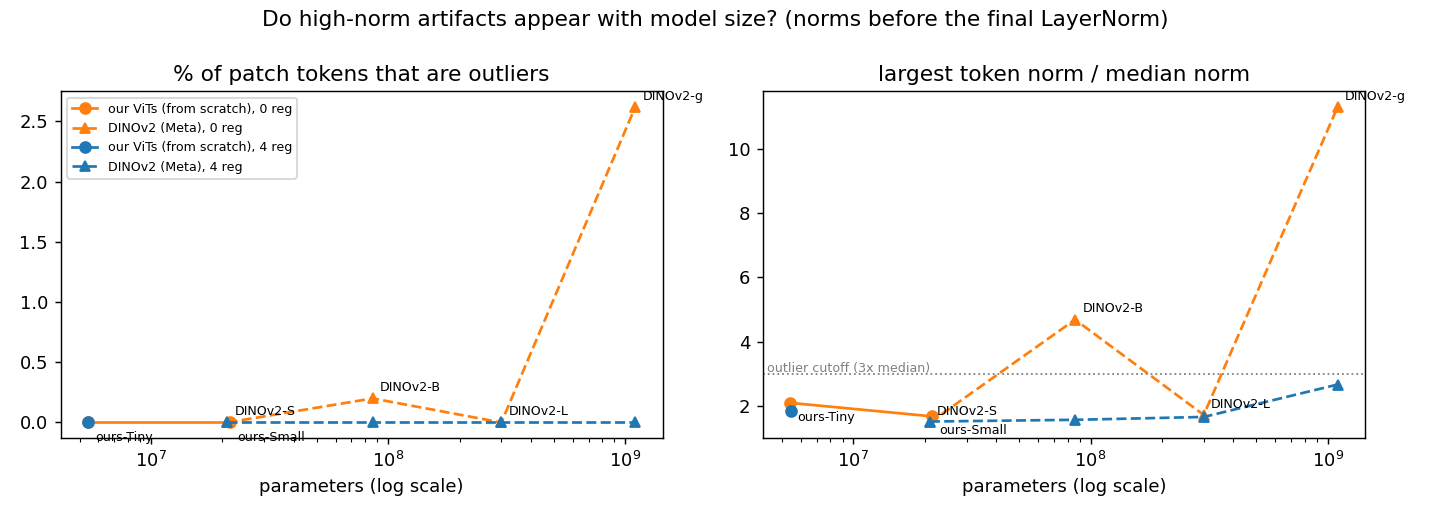

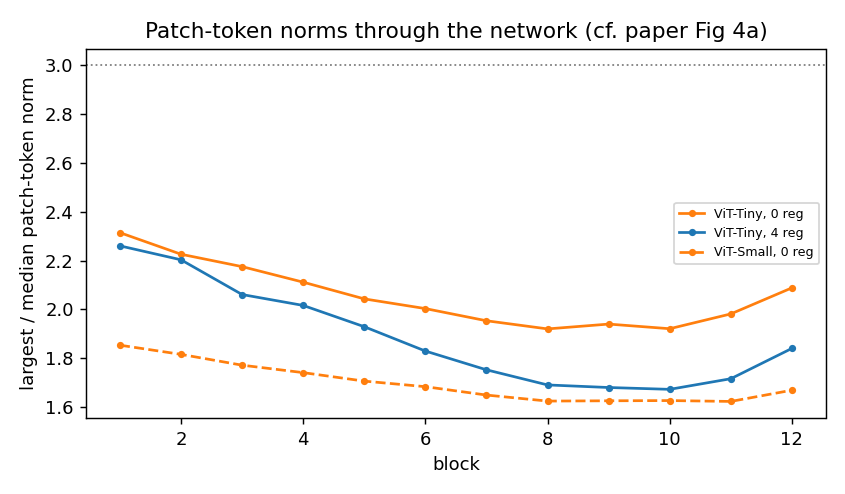

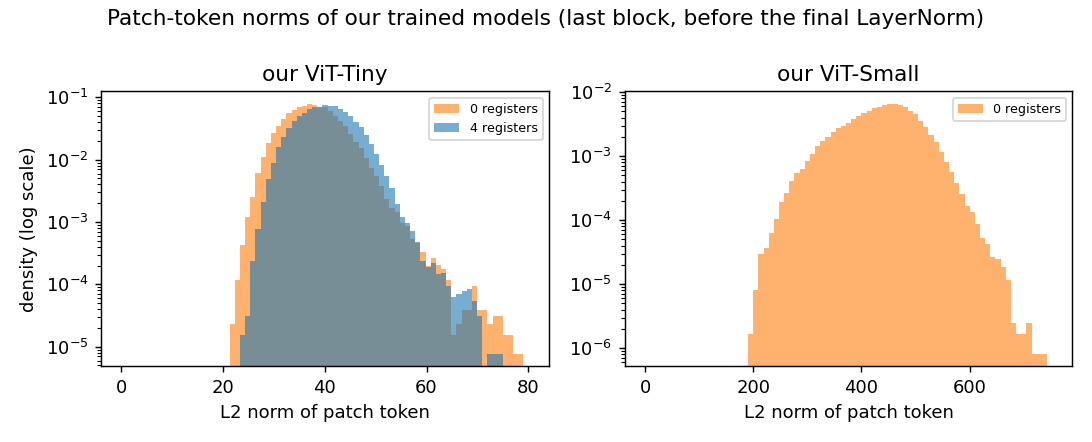

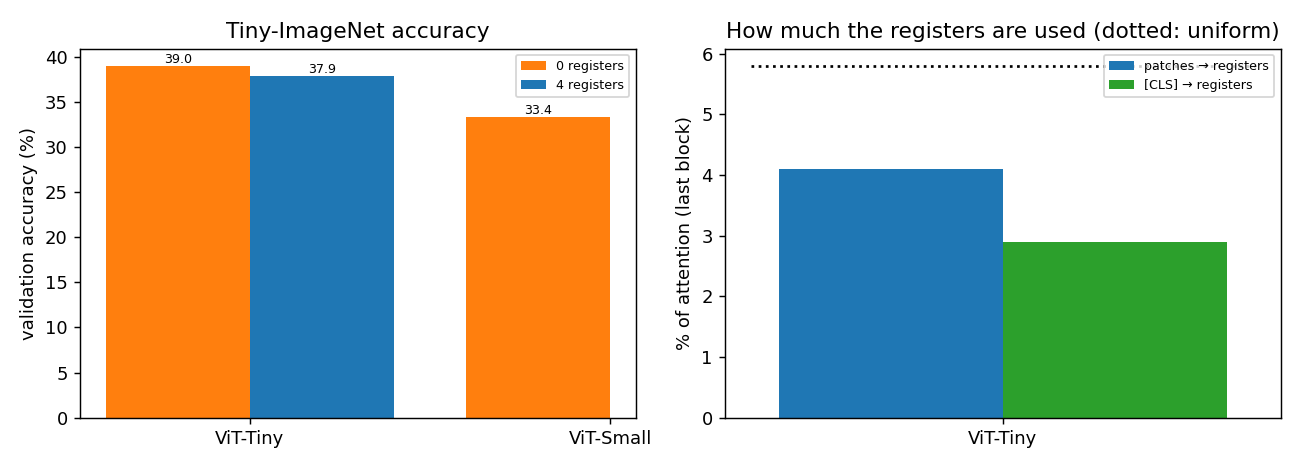

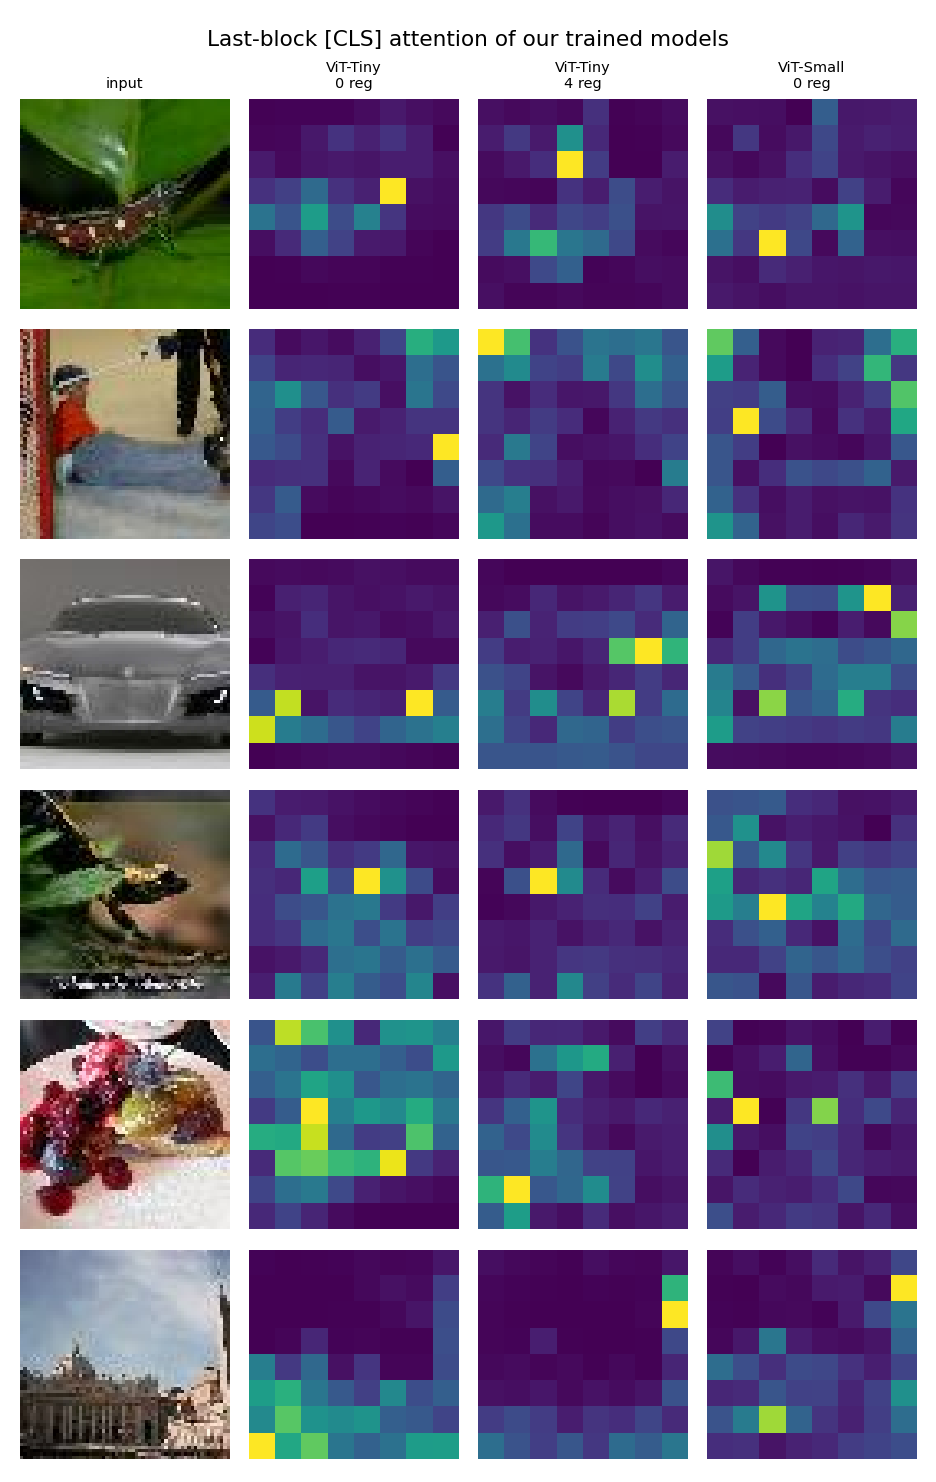

In [7]:
!python -m scripts.summarise_experiment
display(Markdown(open("results/experiment/summary.md").read().split("![")[0]))
for name in ["scaling", "layer_norms", "norm_histograms", "accuracy_registers", "attention_maps", "learning_rate"]:
    if os.path.exists(f"results/figures/experiment_{name}.png"):
        display(Image(f"results/figures/experiment_{name}.png"))

## 7. Download the results
Small files only (no training checkpoints). Send this zip in; one zip per account.

In [8]:
import glob
paths = [f"results/experiment/{r}" for r in RUNS] + [f"results/runs/{r}" for r in RUNS if os.path.exists(f"results/runs/{r}")]
paths += glob.glob("app/weights/*.pt")
name = "experiment_" + "_".join(RUNS) + ".zip"
targets = " ".join(paths)
!zip -qr {name} {targets}
from google.colab import files
files.download(name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>